In [28]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.tree import DecisionTreeClassifier

In [29]:
df=pd.read_csv("student_performance.csv")

In [30]:
df.head(5)

,Study_Hours,Attendance,Previous_Marks,Result
0,1,45,30,Fail
1,2,50,35,Fail
2,3,55,40,Fail
3,4,60,45,Fail
4,5,65,50,Pass


In [31]:
def cond(v):
    if v=="Pass":
        return 1
    else:
        return 0
df["Res"]=df["Result"].apply(cond)

In [32]:
df.drop(columns=["Result"],inplace=True)

In [33]:
df.columns

Index(['Study_Hours', 'Attendance', 'Previous_Marks', 'Res'], dtype='str')

In [34]:
x=df.drop(columns=["Res"])
y=df["Res"]


In [35]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [37]:
models={
    "logistic":LogisticRegression(),
    "naivebayes":CategoricalNB(),
    "RandomForestClassifier":RandomForestClassifier(),
    "DecisionTreeClassifier":DecisionTreeClassifier(),
    "AdaBoostClassifier":AdaBoostClassifier(),
    "KnearestNeighbors":KNeighborsClassifier(),
    "SVC":SVC()
}

In [38]:
from sklearn.metrics import accuracy_score

In [39]:
best_model=None
best_score=0
for name, model in models.items():
    model.fit(x_train,y_train)
    pred=model.predict(x_test)
    accuracy=accuracy_score(y_test,pred)
    if(accuracy>best_score):
        best_score=accuracy
        best_model=model
print("Best Model:",best_model)
print("Best Accuracy:",best_score)

Best Model: LogisticRegression()
Best Accuracy: 1.0


In [40]:
import pickle

In [41]:
with open("model.pkl","wb")as file:
    pickle.dump(best_model,file)

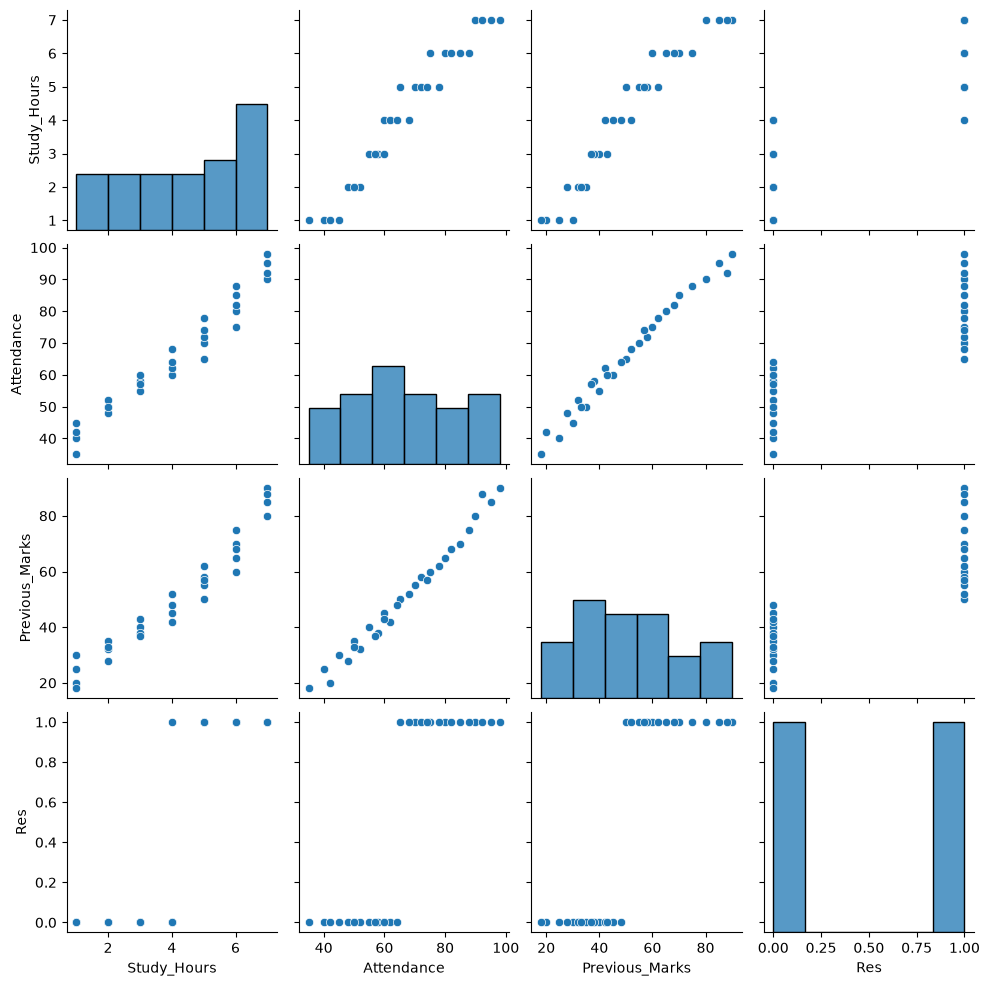

In [42]:
import seaborn as sns
sns.pairplot(df)

<Axes: xlabel='Study_Hours', ylabel='count'>

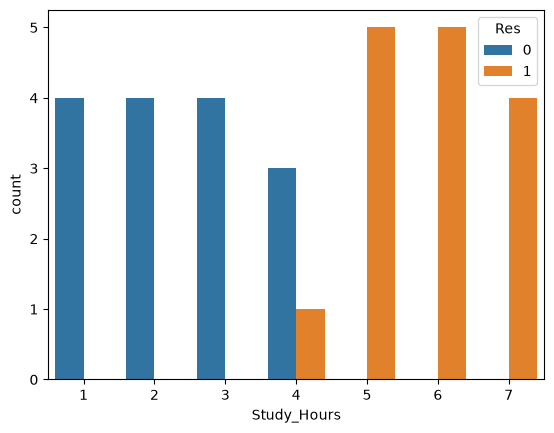

In [43]:
sns.countplot(x=df["Study_Hours"],hue=df["Res"])

In [45]:
print(df.corr())

                Study_Hours  Attendance  Previous_Marks       Res
Study_Hours        1.000000    0.975895        0.967216  0.861934
Attendance         0.975895    1.000000        0.991321  0.844639
Previous_Marks     0.967216    0.991321        1.000000  0.837553
Res                0.861934    0.844639        0.837553  1.000000
